# 几何探针对比：VGGT 与 3DRAE

**问题：** 同样的探针，读 VGGT 的 token 和读 3DRAE 的 token，哪个能更准地给出物体位置？

**做法：** 探针、数据、真值、损失、训练设置都与 3DRAE 实验相同（见 `README.md` 和 `report_probe.md`），只把被读取的 token 换成 VGGT 的：

- **VGGT token：** 冻结的 VGGT-1B aggregator 最后一轮的 patch token（frame 和 global 两半拼接，2048 维）。VGGT 只看 8 帧图像，不输入相机位姿，以第一帧为参考系，和真值的坐标系一致。
- **相机信息：** 和 DINOv2 对照一样，每个 patch token 加上它的 Plücker 射线（来自真值相机，经可训练线性层）和视图编号嵌入。这样三种 token 拿到的相机信息相同。
- **两种输入分辨率：** 224×308（和 3DRAE 相同，8 帧共 2816 个 token）；378×518（VGGT 训练时的宽度，8 帧共 7992 个 token）。
- **两种查询：** 物体名称提示（类别名的文本嵌入）；点提示（物体中心投影处的 DINOv2 patch 特征加该像素射线，所有 token 来源共用同一种查询）。

**怎么读表：** 物体名称提示统计 EmbodiedScan 标注为可见的物体；点提示统计中心至少落在一帧画面内的物体。验证集 229 个场景，方括号内是按场景 bootstrap 的 95% 置信区间。每组只跑了一个随机种子。

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "outputs" / "geo_probe").is_dir())
RUNS = ROOT / "outputs" / "geo_probe"
pd.set_option("display.width", 200)

CATEGORY = {"3DRAE": "real", "DINOv2 patch": "dino_real", "VGGT 224x308": "vggt_real",
            "VGGT 378x518": "vggt518_real", "shuffled 3DRAE (floor)": "shuffled"}
POINT = {"3DRAE": "point_3drae_real", "DINOv2 patch": "point_dino_real", "VGGT 224x308": "point_vggt_real",
         "VGGT 378x518": "point_vggt518_real", "shuffled 3DRAE (floor)": "point_3drae_shuffled"}
METRICS = [("position_m", "position error (m)", 2), ("distance_m", "pair distance error (m)", 2),
           ("azimuth_deg", "azimuth error (deg)", 1), ("quadrant_acc", "quadrant acc (%)", 1),
           ("lrb_acc", "left/right/back acc (%)", 1)]
COLORS = {"3DRAE": "#2a78d6", "DINOv2 patch": "#8a8f98", "VGGT 224x308": "#eb6834", "VGGT 378x518": "#b23c0c",
          "shuffled 3DRAE (floor)": "#c8ccd2"}


def final(run):
    path = RUNS / run / "final_metrics.json"
    return json.loads(path.read_text()) if path.exists() else None


def table(runs, group):
    rows = {}
    for name, run in runs.items():
        result = final(run)
        if result is None:
            continue
        row = {}
        for key, label, digits in METRICS:
            m = result["eval_real"][f"{group}/{key}"]
            k = 100 if key.endswith("_acc") else 1
            row[label] = f"{m['value'] * k:.{digits}f} [{m['ci95'][0] * k:.{digits}f}, {m['ci95'][1] * k:.{digits}f}]"
        s = result["eval_shuffled"]
        row["tokens swapped at eval: position (m) / quadrant (%)"] = (
            f"{s[f'{group}/position_m']['value']:.2f} / {s[f'{group}/quadrant_acc']['value'] * 100:.1f}")
        row["n objects"] = result["eval_real"][f"{group}/position_m"]["n"]
        rows[name] = row
    return pd.DataFrame(rows).T


def bars(runs, group, title):
    shown = [(n, final(r)) for n, r in runs.items() if final(r)]
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
    for ax, (key, label, _) in zip(axes, [METRICS[0], METRICS[2], METRICS[3]]):
        k = 100 if key.endswith("_acc") else 1
        values = [r["eval_real"][f"{group}/{key}"] for _, r in shown]
        y = np.array([m["value"] * k for m in values])
        err = np.array([[m["value"] - m["ci95"][0], m["ci95"][1] - m["value"]] for m in values]).T * k
        ax.bar(range(len(y)), y, yerr=err, color=[COLORS[n] for n, _ in shown], capsize=3)
        for i, v in enumerate(y):
            ax.text(i, v + err[1][i], f"{v:.2f}" if k == 1 and v < 10 else f"{v:.1f}", ha="center", va="bottom", fontsize=9)
        ax.set_xticks(range(len(y)), [n.replace(" ", "\n", 1) for n, _ in shown], fontsize=8)
        ax.set_title(label, fontsize=10)
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    plt.show()

## 1. 物体名称提示（可见物体）

In [2]:
category_table = table(CATEGORY, "visible")
category_table

,position error (m),pair distance error (m),azimuth error (deg),quadrant acc (%),left/right/back acc (%),tokens swapped at eval: position (m) / quadrant (%),n objects
3DRAE,"0.95 [0.86, 1.05]","0.64 [0.57, 0.71]","42.8 [39.0, 46.4]","45.6 [43.3, 48.9]","54.5 [52.3, 57.1]",2.10 / 39.2,5620
DINOv2 patch,"0.94 [0.86, 1.03]","0.65 [0.59, 0.71]","34.5 [30.7, 38.2]","51.3 [48.6, 54.3]","60.0 [57.6, 63.0]",1.98 / 41.6,5620
VGGT 224x308,"1.45 [1.34, 1.58]","0.81 [0.73, 0.89]","56.9 [52.5, 60.1]","37.2 [35.3, 39.0]","46.3 [44.6, 48.5]",2.07 / 35.2,5620
VGGT 378x518,"1.46 [1.33, 1.59]","0.81 [0.74, 0.89]","57.3 [53.6, 60.2]","37.1 [35.6, 38.9]","46.4 [44.6, 48.5]",2.09 / 34.8,5620
shuffled 3DRAE (floor),"1.85 [1.73, 1.96]","1.08 [1.01, 1.15]","65.7 [62.7, 67.4]","33.3 [32.0, 34.5]","42.5 [41.2, 43.8]",1.84 / 33.3,5620


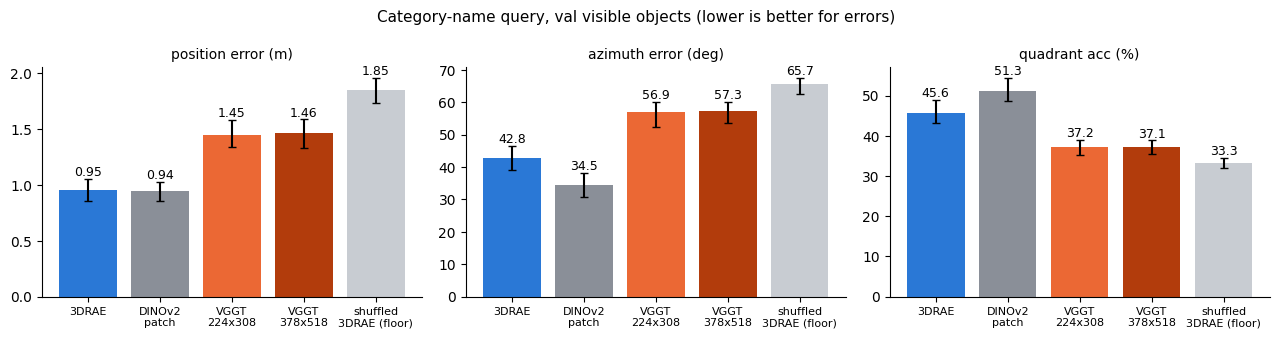

In [3]:
bars(CATEGORY, "visible", "Category-name query, val visible objects (lower is better for errors)")

## 2. 点提示（中心在画面内的物体）

In [4]:
point_table = table(POINT, "all")
point_table

,position error (m),pair distance error (m),azimuth error (deg),quadrant acc (%),left/right/back acc (%),tokens swapped at eval: position (m) / quadrant (%),n objects
3DRAE,"0.27 [0.25, 0.30]","0.21 [0.19, 0.25]","8.0 [7.2, 8.8]","83.3 [81.9, 84.8]","87.8 [86.8, 88.8]",1.17 / 66.8,4949
DINOv2 patch,"0.52 [0.48, 0.56]","0.42 [0.37, 0.48]","10.8 [9.9, 11.7]","78.9 [77.2, 80.6]","84.4 [83.0, 85.6]",1.15 / 65.1,4949
VGGT 224x308,"0.29 [0.27, 0.31]","0.24 [0.21, 0.27]","7.8 [7.0, 8.7]","83.2 [81.4, 85.1]","87.8 [86.4, 89.0]",1.03 / 70.8,4949
VGGT 378x518,"0.26 [0.24, 0.28]","0.20 [0.18, 0.23]","7.4 [6.6, 8.4]","83.3 [81.5, 85.2]","87.7 [85.9, 89.0]",1.04 / 70.7,4949
shuffled 3DRAE (floor),"0.67 [0.61, 0.74]","0.55 [0.48, 0.65]","15.5 [14.4, 16.4]","71.5 [69.6, 73.6]","79.0 [77.5, 80.5]",0.68 / 71.4,4949


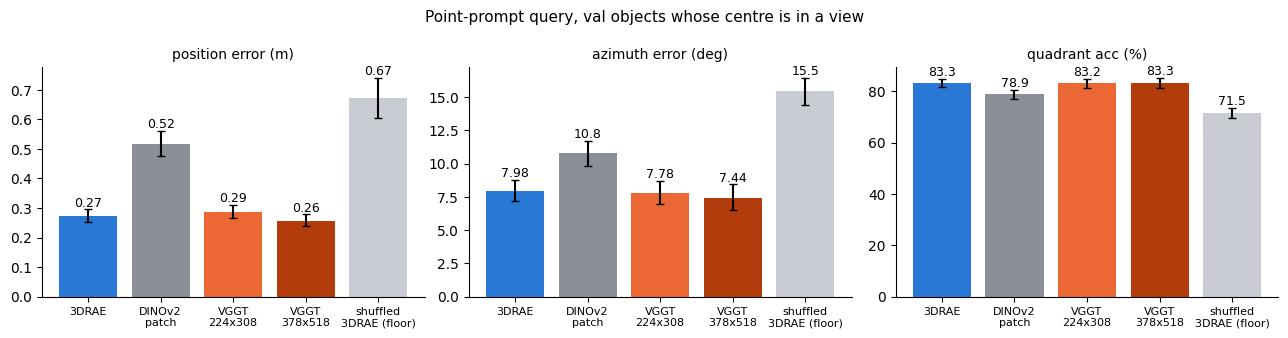

In [5]:
bars(POINT, "all", "Point-prompt query, val objects whose centre is in a view")

## 3. 误差分解

按类别在训练集中的出现次数、物体到第一帧相机的距离分组，看位置误差中位数（米）。只统计中心至少在一帧画面内的物体。如果误差随出现次数明显下降，说明探针受“认出物体”限制；点提示下应当基本持平。

In [6]:
FREQ = [(0, 0, "0"), (1, 9, "1-9"), (10, 49, "10-49"), (50, 199, "50-199"), (200, 10**9, "200+")]
DIST = [(0, 2, "0-2 m"), (2, 3, "2-3 m"), (3, 4, "3-4 m"), (4, 6, "4-6 m")]


def objects(run):
    path = RUNS / run / "analysis_objects.jsonl"
    if not path.exists():
        return None
    frame = pd.DataFrame([json.loads(line) for line in path.open()])
    return frame[frame.views_seeing_centre > 0]


def breakdown(runs, column, bins, closed_right):
    out = {}
    for name, run in runs.items():
        frame = objects(run)
        if frame is None:
            continue
        row = {}
        for lo, hi, label in bins:
            sel = frame[(frame[column] >= lo) & ((frame[column] <= hi) if closed_right else (frame[column] < hi))]
            row[f"{label} (n={len(sel)})" if name == next(iter(runs)) else label] = sel.error.median()
        out[name] = list(row.values())
        labels = list(row) if name == next(iter(runs)) else labels
    return pd.DataFrame(out, index=labels).T.round(2)


print("position error (m) by category frequency in train")
display(pd.concat({"category query": breakdown(CATEGORY, "train_freq", FREQ, True),
                   "point prompt": breakdown(POINT, "train_freq", FREQ, True)}))
print("position error (m) by object distance from the first camera")
display(pd.concat({"category query": breakdown(CATEGORY, "gt_dist_from_cam0", DIST, False),
                   "point prompt": breakdown(POINT, "gt_dist_from_cam0", DIST, False)}))

position error (m) by category frequency in train


0 (n=29)  1-9 (n=139)  10-49 (n=860)  50-199 (n=2925)  200+ (n=996)
category query 3DRAE                       2.78         1.57           1.32             0.90          0.65
               DINOv2 patch                2.65         1.51           1.26             0.94          0.72
               VGGT 224x308                2.95         1.70           1.69             1.50          1.11
               VGGT 378x518                2.58         1.77           1.81             1.50          1.10
               shuffled 3DRAE (floor)      2.79         2.06           1.97             1.96          1.70
point prompt   3DRAE                       0.42         0.35           0.29             0.27          0.27
               DINOv2 patch                0.71         0.67           0.52             0.51          0.51
               VGGT 224x308                0.32         0.39           0.30             0.29          0.27
               VGGT 378x518                0.38         0.39           0.28             0.25          0.24
               shuffled 3DRAE (floor)      0.91         0.93           0.66             0.67          0.69

position error (m) by object distance from the first camera


0-2 m (n=2453)  2-3 m (n=1540)  3-4 m (n=617)  4-6 m (n=298)
category query 3DRAE                             0.69            1.04           1.44           2.17
               DINOv2 patch                      0.69            1.10           1.43           2.32
               VGGT 224x308                      1.10            1.75           2.09           2.67
               VGGT 378x518                      1.12            1.72           2.08           2.77
               shuffled 3DRAE (floor)            1.31            2.29           3.17           4.41
point prompt   3DRAE                             0.22            0.28           0.40           0.60
               DINOv2 patch                      0.40            0.58           0.71           1.11
               VGGT 224x308                      0.23            0.31           0.41           0.65
               VGGT 378x518                      0.21            0.28           0.36           0.59
               shuffled 3DRAE (floor)            0.48            0.87           0.94           1.37

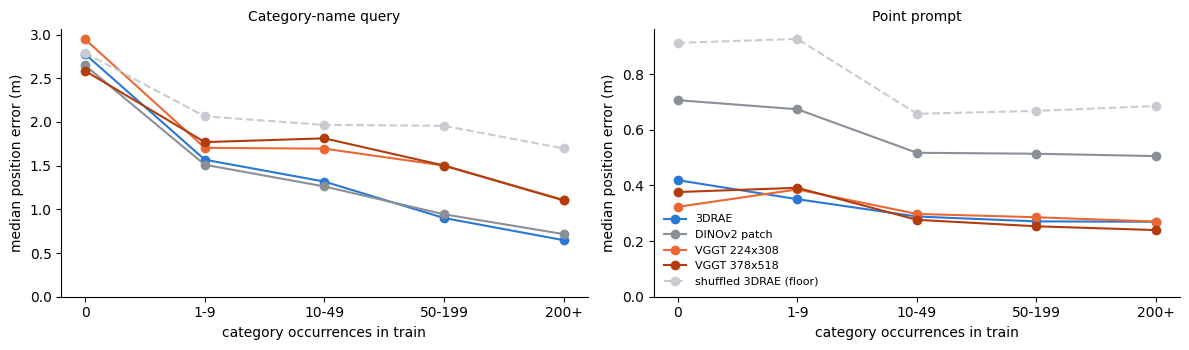

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=False)
for ax, (title, runs) in zip(axes, [("Category-name query", CATEGORY), ("Point prompt", POINT)]):
    for name, run in runs.items():
        frame = objects(run)
        if frame is None:
            continue
        y = [frame[(frame.train_freq >= lo) & (frame.train_freq <= hi)].error.median() for lo, hi, _ in FREQ]
        ax.plot(range(len(FREQ)), y, marker="o", color=COLORS[name], label=name,
                linestyle="--" if "shuffled" in name else "-")
    ax.set_xticks(range(len(FREQ)), [b[2] for b in FREQ])
    ax.set_xlabel("category occurrences in train")
    ax.set_ylabel("median position error (m)")
    ax.set_title(title, fontsize=10)
    ax.set_ylim(bottom=0)
    ax.spines[["top", "right"]].set_visible(False)
axes[1].legend(fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

## 4. 注意力检查（物体名称提示）

DINOv2 和 VGGT 的 token 都对应图像 patch，所以可以看探针第 1 层 cross-attention 落在物体中心投影周围 7×7 个 patch 内的比例，相对均匀分布的倍数。倍数越高，说明探针越能根据名字找到物体。注意 378×518 的 patch 更小，7×7 窗口覆盖的图像范围也更小，和 224×308 的倍数不能直接比。

In [8]:
rows = {}
for name in ("DINOv2 patch", "VGGT 224x308", "VGGT 378x518"):
    frame = objects(CATEGORY[name])
    if frame is None or "attn_l1_r3" not in frame:
        continue
    frame = frame.dropna(subset=["attn_l1_r3"])
    row = {}
    for lo, hi, label in FREQ:
        sel = frame[(frame.train_freq >= lo) & (frame.train_freq <= hi)]
        row[f"freq {label}"] = sel.attn_l1_r3.mean() / sel.uniform_r3.mean()
    cuts = frame.attn_l1_r3.quantile([1 / 3, 2 / 3]).values
    tertile = np.searchsorted(cuts, frame.attn_l1_r3)
    for k, label in enumerate(("low", "mid", "high")):
        row[f"error (m), {label} attention"] = frame.error[tertile == k].median()
    rows[name] = row
pd.DataFrame(rows).T.round(2)

,freq 0,freq 1-9,freq 10-49,freq 50-199,freq 200+,"error (m), low attention","error (m), mid attention","error (m), high attention"
DINOv2 patch,1.47,2.13,5.01,6.74,8.17,1.41,0.90,0.76
VGGT 224x308,1.02,1.23,1.35,1.34,2.68,1.75,1.52,1.21
VGGT 378x518,1.10,1.40,1.30,1.20,1.75,1.57,1.58,1.35


## 5. 训练曲线

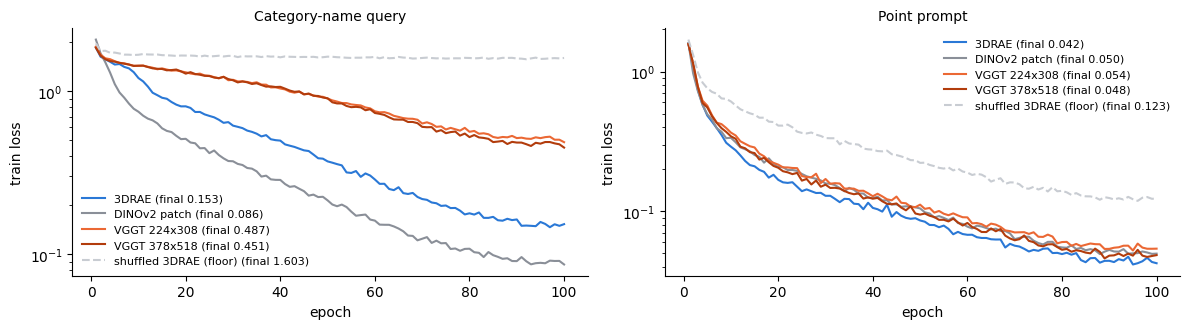

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, (title, runs) in zip(axes, [("Category-name query", CATEGORY), ("Point prompt", POINT)]):
    for name, run in runs.items():
        path = RUNS / run / "metrics.jsonl"
        if not path.exists():
            continue
        log = pd.DataFrame([json.loads(line) for line in path.open()]).drop_duplicates("epoch", keep="last")
        ax.plot(log.epoch, log.loss, color=COLORS[name], label=f"{name} (final {log.loss.iloc[-1]:.3f})",
                linestyle="--" if "shuffled" in name else "-")
    ax.set_yscale("log")
    ax.set_xlabel("epoch")
    ax.set_ylabel("train loss")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8, frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 6. 结论

任务 12545–12548（训练）、12554（误差分解和注意力）。

| | 3DRAE | VGGT 224×308 | VGGT 378×518 | DINOv2 patch | 打乱 3DRAE（下限） |
|---|---|---|---|---|---|
| 点提示：位置误差 | 0.27 m | 0.29 m | 0.26 m | 0.52 m | 0.67 m |
| 点提示：方位角误差 | 8.0° | 7.8° | 7.4° | 10.8° | 15.5° |
| 点提示：四象限准确率 | 83.3% | 83.2% | 83.3% | 78.9% | 71.5% |
| 名称提示：位置误差 | 0.95 m | 1.45 m | 1.46 m | 0.94 m | 1.85 m |
| 名称提示：方位角误差 | 42.8° | 56.9° | 57.3° | 34.5° | 65.7° |
| 名称提示：四象限准确率 | 45.6% | 37.2% | 37.1% | 51.3% | 33.3% |
| 名称提示：最终训练 loss | 0.15 | 0.49 | 0.45 | 0.09 | 1.60 |

**1. 点提示下，VGGT 和 3DRAE 的几何精度相同。** 位置误差 0.26–0.29 m 对 0.27 m，置信区间互相重叠；方位角和四象限准确率也几乎一样。两者都比 DINOv2 patch 好约一倍。也就是说，在“已知物体在哪个像素”的条件下，3DRAE 的 1024 个 scene token 保留的位置信息不比 VGGT 的 2816 / 7992 个 patch token 少。

**2. 名称提示下，VGGT 明显更差。** 位置误差 1.45 m，四象限准确率 37%，只比打乱 token 的下限（1.85 m，33.3%）好一点，远不如 3DRAE（0.95 m，45.6%）和 DINOv2（0.94 m，51.3%）。各个类别频率档都更差，出现 200 次以上的类别也有 1.1 m（3DRAE 为 0.65 m）。

**3. 原因是探针没法根据名字在 VGGT token 里找到物体。** 第 1 层注意力落在物体周围 7×7 patch 内的比例，VGGT 基本接近均匀分布（1.0–1.4 倍，只有最常见的类别到 2.7 倍），DINOv2 是 5–8 倍。训练 loss 也说明同一件事：VGGT 的名称提示探针连训练集都没拟合好（0.49，DINOv2 为 0.09，3DRAE 为 0.15）。VGGT 最后一轮的 token 是为几何任务训练的，物体类别信息比 DINOv2 特征难读出来。

**4. 分辨率影响很小。** 378×518 在点提示下略好（0.26 m 对 0.29 m），在名称提示下没有区别。

**对主线的含义：** 换成 VGGT 不会改善空间理解。几何精度两者持平，而“把物体名对应到 token”这一步，VGGT 的 token 比 3DRAE 的更难。瓶颈仍然是语言和视觉的对齐，3DRAE 在这一点上反而更有利。

**注意事项**
- 每组只跑一个随机种子。
- VGGT 只用了最后一轮的 token。中间层可能保留更多语义信息，没有测。
- VGGT 名称提示的训练 loss 在第 100 个 epoch 仍在下降，训练更久可能缩小差距；但验证误差从第 80 个 epoch 起只从 1.44 m 变到 1.45 m，改善空间有限。
- 三种 token 都加了真值相机射线。VGGT 本身不需要位姿输入，这里没有测不给位姿的情况。
- 点提示的查询用的是 DINOv2 特征加真值投影位置，属于理想定位，不代表模型自己找物体时的精度。
